# Assignment 1: Training Simple Neural Networks
Name:   ZENZ Sebastian\
MatNr:  01031159

For this assignment PyTorch is used to train a neural network for a regression task on California Housing Dataset with the goal of predicting the housing value based on verious preductive variables. In part (d) the problem is re-formulated as a binary classification problem.

## 1. Imports and reproducibility

Set seeds so repeated runs are more comparable. `DEVICE` uses a GPU if PyTorch can access one; otherwise, computation runs on the CPU.

In [ ]:
from copy import deepcopy
from itertools import product
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# rng seed
SEED = 302          # random_state=302 was used in assignment sheet, so we use it here as well
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# from housing dataset
FEATURE_NAMES = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude",
]

# use gpu if compatible/available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    print("GPU used:", torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
GPU used: NVIDIA GeForce RTX 4080 SUPER


## 2. Load and inspect the data

The provided split reserves 25% of the data for final testing. Do not use that test split to choose a model or hyperparameters.\
X is storing the features, y is storing the target values (value of house in $100k)

In [7]:
def load_data():
    # import query from assignment sheet
    X, y = fetch_california_housing(return_X_y=True)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=SEED
    )
    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = load_data()
print(f"Training features: {X_train.shape}; training targets: {y_train.shape}")
print(f"Test features: {X_test.shape}; test targets: {y_test.shape}")
pd.DataFrame(X_train, columns=FEATURE_NAMES).head(6)

Training features: (15480, 8); training targets: (15480,)
Test features: (5160, 8); test targets: (5160,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,3.3409,32.0,3.254902,1.009804,177.0,1.735294,33.90,-118.37
1,4.0000,35.0,4.938095,0.985714,552.0,2.628571,37.71,-122.12
2,4.1997,17.0,5.732759,1.060345,2866.0,3.088362,38.66,-121.76
3,5.6163,27.0,6.515670,1.005698,1140.0,3.247863,33.83,-117.87
4,1.6559,48.0,5.161663,1.000000,1363.0,3.147806,33.99,-118.31
5,2.3023,37.0,4.926952,1.012594,1265.0,3.186398,37.74,-120.93


## 3. Explore the training features

Analyse the target and feature distribution of the training set. Histograms are used to visualize data

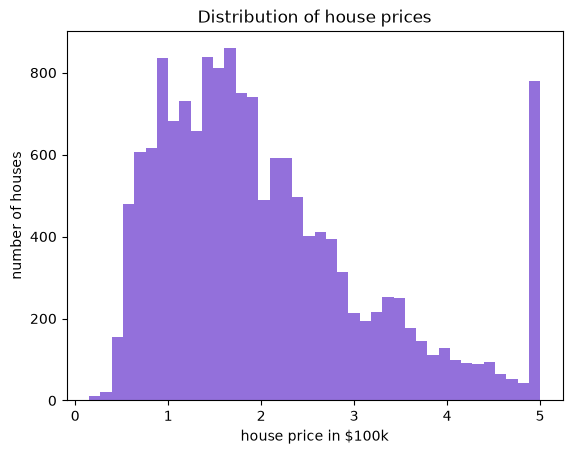

,medHouseVal
count,15480.000000
mean,2.068206
std,1.156928
min,0.149990
25%,1.189000
50%,1.798000
75%,2.647000
max,5.000010


In [8]:
# targets
plt.hist(y_train, bins=40, color="mediumpurple")
plt.xlabel("house price in $100k")
plt.ylabel("number of houses")
plt.title("Distribution of house prices")
plt.show()

frame = pd.DataFrame({"medHouseVal": y_train})
frame.describe()

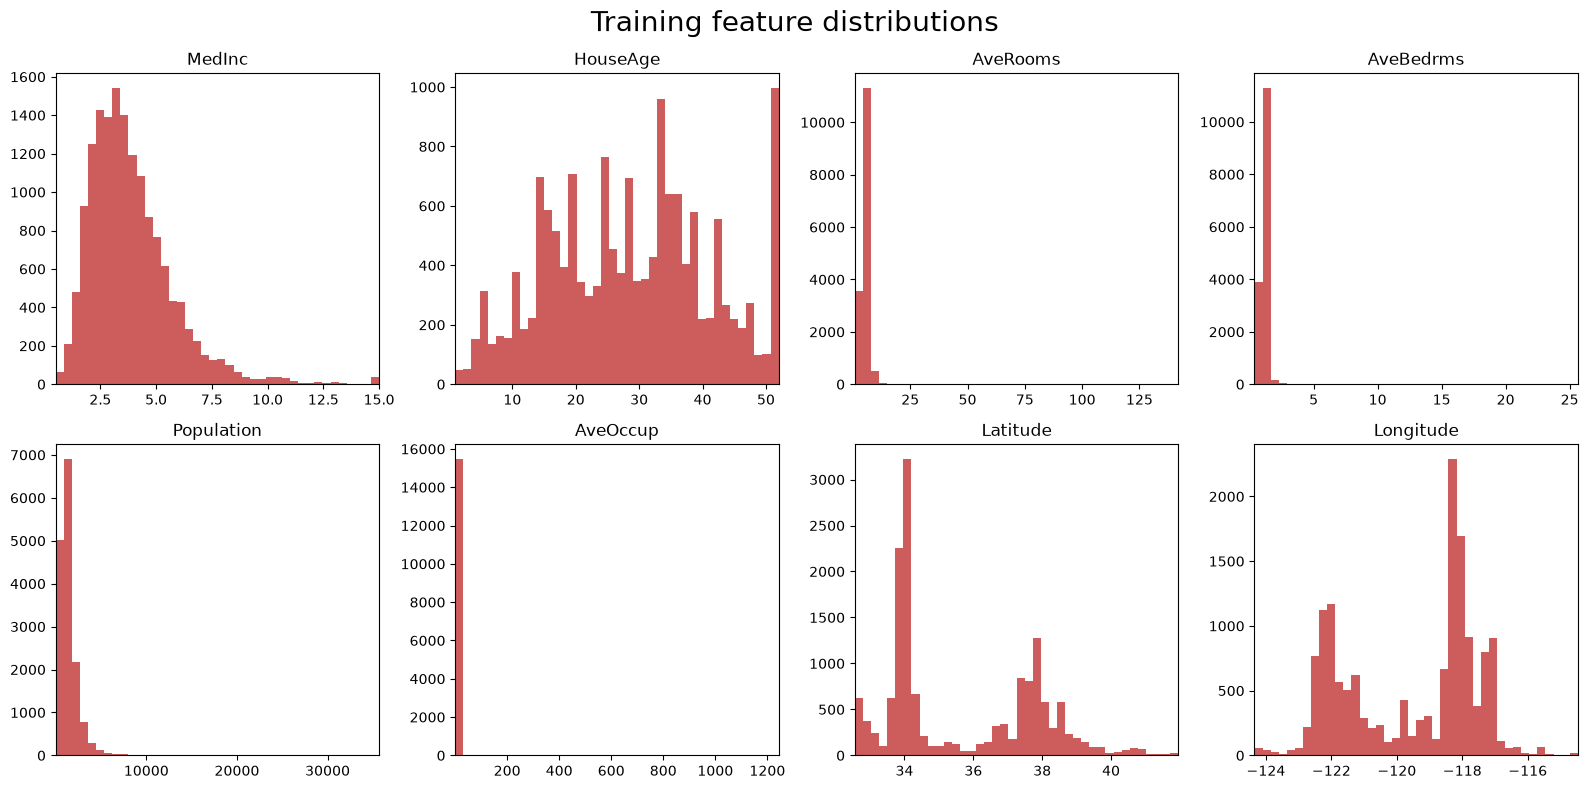

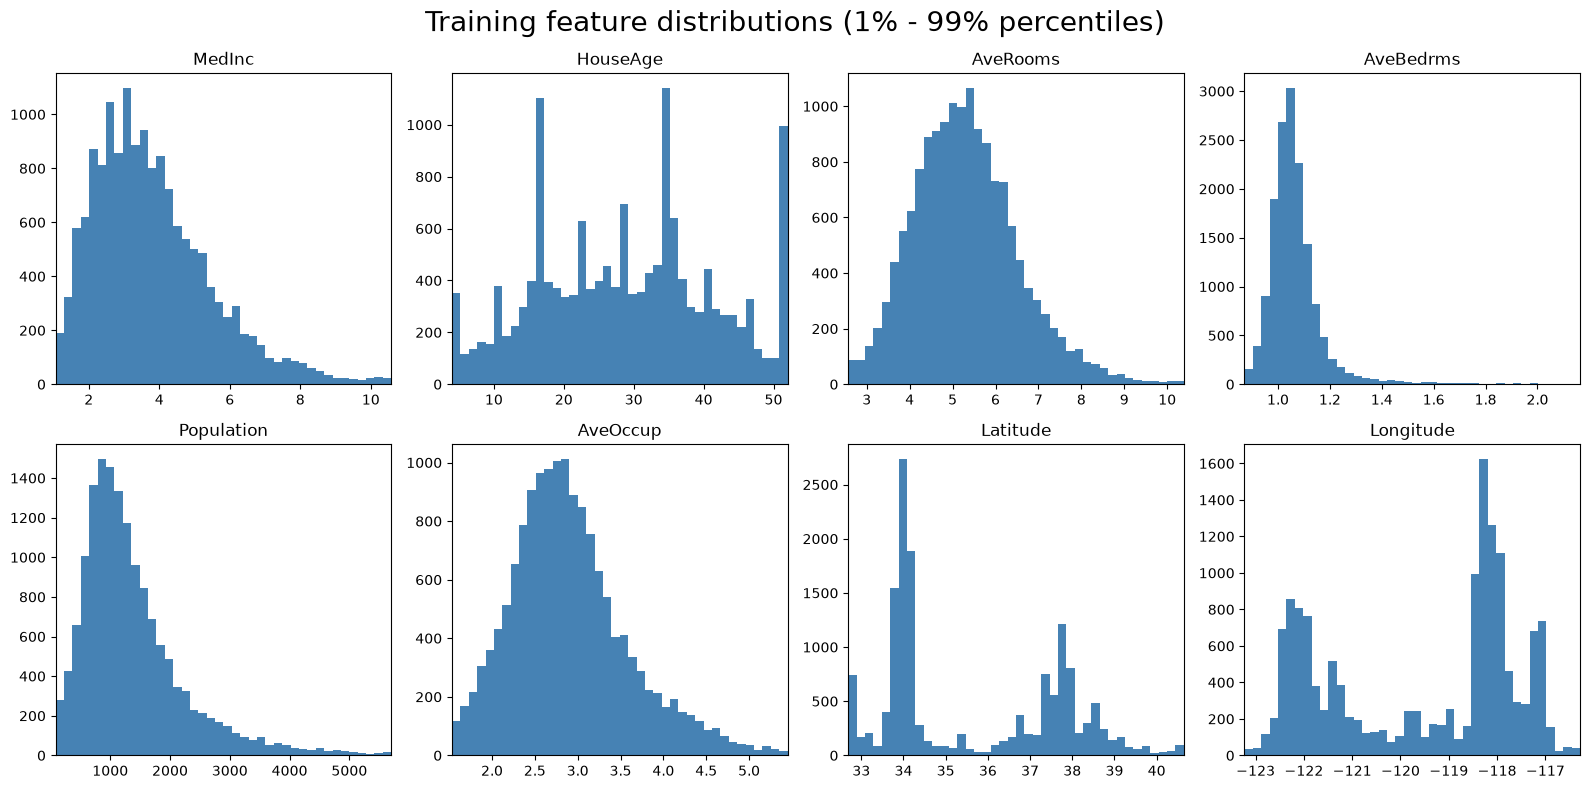

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000
mean,3.867932,28.634044,5.431607,1.095960,1421.528811,3.112156,35.634422,-119.569263
std,1.899344,12.642321,2.388734,0.427406,1124.197972,11.959223,2.138867,2.004747
min,0.499900,1.000000,0.846154,0.375000,3.000000,0.692308,32.560000,-124.350000
25%,2.565800,18.000000,4.443769,1.006118,787.000000,2.431797,33.930000,-121.790000
50%,3.528800,29.000000,5.230702,1.048833,1163.000000,2.823972,34.250000,-118.490000
75%,4.744150,37.000000,6.060497,1.099431,1719.250000,3.282093,37.720000,-118.000000
max,15.000100,52.000000,141.909091,25.636364,35682.000000,1243.333333,41.950000,-114.470000


In [ ]:
# features
def analyse_features(X_set, color="steelblue", lower_pc=0, upper_pc=1):
    frame = pd.DataFrame(X_set, columns=FEATURE_NAMES)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    for ax, feature in zip(axes.flat, frame.columns):
        values = frame[feature]

        #ax.hist(values, bins=40)
        lower, upper = values.quantile([lower_pc, upper_pc])
        ax.hist(values, bins=40, range=(lower, upper),color=color)
        ax.set_xlim(lower, upper)

        ax.set_title(feature)

    if lower_pc != 0 and upper_pc != 1:
        plt.suptitle(f"Training feature distributions ({lower_pc:.0%} - {upper_pc:.0%} percentiles)",fontsize=20)
    else:
        plt.suptitle("Training feature distributions",fontsize=20)
    plt.tight_layout()
    plt.show()
    return frame.describe()

analyse_features(X_train,color="indianred")
analyse_features(X_train,lower_pc=0.01,upper_pc=0.99)   # 1-99% percentile

## 4. Make a regression training/validation split

The validation data is used to compare candidate models, 20% of the training data is held back for validation in this case.\
The subsets are then normalized with the `StandardScaler`. Fit the scaler on the SUBTRAINING data only, then use that fitted scaler to transform validation inputs. This avoids leaking information from validation into preprocessing.


In [11]:
X_subtrain, X_valid, y_subtrain, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED
)

scaler = StandardScaler()
X_subtrain_scaled = scaler.fit_transform(X_subtrain)
X_valid_scaled = scaler.transform(X_valid)
print(f"Subtraining: {X_subtrain_scaled.shape}; validation: {X_valid_scaled.shape}")

Subtraining: (12384, 8); validation: (3096, 8)


## 5. Defining the network and dataloader implementation

The network has fully connected `Linear` layers and `ReLU` activations. For regression, its output is one unrestricted value because the target is continuous (house value).\
A `DataLoader` supplies mini-batches. 

In [ ]:
# Defining the network
class FeedForwardNetwork(nn.Module):
    def __init__(self, hidden_units, output_units=1):
        super().__init__()
        layers = []
        input_units = len(FEATURE_NAMES)                                    # e.g. 8 features = 8 input neurons
        for units in hidden_units:                                          # tupels e.g. (8,8,8) = 3 hidden layers with 8 hidden units
            layers.extend([nn.Linear(input_units, units),nn.ReLU()])        # layer + ReLU nonLin
            input_units = units
        layers.append(nn.Linear(input_units, output_units))                 # output layer = 1 outpur neuron (1 target val regression)
        self.network = nn.Sequential(*layers)                               # unpack layer list and feed the network (sequential)

    def forward(self, x):
        return self.network(x)

In [14]:
# Dataloader
def make_loader(X, y, batch_size, shuffle):
    x_tensor = torch.as_tensor(X, dtype=torch.float32)
    y_tensor = torch.as_tensor(y, dtype=torch.float32).reshape(-1, 1)
    dataset = TensorDataset(x_tensor, y_tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

## 6. Implement the training algorithm
Several configurations are tested and stores for reporting.

In [49]:
# configurations
configurations = []
learning_rate = 0.01
epochs = 100
batch_size = 64
config_idx = 1

# 12 configurations with N hidden layers x M hidden units {2^(N,M)}
for var_units in range(4,8):    # 2^4 to 2^7 = 16,32,64,128
    for var_layers in range(1,4):       # 2^1 to 2^3 = 2,4,8
        config_description =f"Config_{config_idx:02}: {2**var_layers} x {2**var_units}"        
        hidden_units = (2**var_units,)*(2**var_layers)     # make tuples for iterator (N=len, M=val)
        
        configurations.append({
            "config_description": config_description,
            "hidden_units": hidden_units,
            "learning_rate": learning_rate,
            "epochs": epochs,
            "batch_size": batch_size,
        })

        config_idx += 1

print("Configs defined by N hidden layers x M hidden units in the layer")
for config in configurations:
    print(f"{config["config_description"]} --> hidden_units = {config["hidden_units"]}")
        


Configs defined by N hidden layers x M hidden units in the layer
Config_01: 2 x 16 --> hidden_units = (16, 16)
Config_02: 4 x 16 --> hidden_units = (16, 16, 16, 16)
Config_03: 8 x 16 --> hidden_units = (16, 16, 16, 16, 16, 16, 16, 16)
Config_04: 2 x 32 --> hidden_units = (32, 32)
Config_05: 4 x 32 --> hidden_units = (32, 32, 32, 32)
Config_06: 8 x 32 --> hidden_units = (32, 32, 32, 32, 32, 32, 32, 32)
Config_07: 2 x 64 --> hidden_units = (64, 64)
Config_08: 4 x 64 --> hidden_units = (64, 64, 64, 64)
Config_09: 8 x 64 --> hidden_units = (64, 64, 64, 64, 64, 64, 64, 64)
Config_10: 2 x 128 --> hidden_units = (128, 128)
Config_11: 4 x 128 --> hidden_units = (128, 128, 128, 128)
Config_12: 8 x 128 --> hidden_units = (128, 128, 128, 128, 128, 128, 128, 128)
